## 1. Import Libraries

In [2]:
#Import libraries
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

from itertools import product

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

#Load the data
df = pd.read_csv(
    "../../data/acdc_dataset.csv",
    sep=";"
)

df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


## 2. Initial data overview

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Unique member IDs: {df['member_id'].nunique():,}")
df.info()


Rows: 15,465
Columns: 31
Unique member IDs: 15,450
<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
member_id,15465,15450,CW015101,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14907.0,NaN,NaN,NaN,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
gender,14935,12,Female,7414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15465,43,Information Technology,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15035,33,Portugal,9959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15465,2,False,11112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15465.0,NaN,NaN,NaN,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_tier,15360,19,flex,5182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15465.0,NaN,NaN,NaN,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
membership_start,15465,1539,2021-01-01,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial observation
The dataset contains 15,465 observations and 31 variables covering member characteristics, membership plans, usage behavior, service usage, renewals, and customer value. The initial summary shows that several variables contain missing values, represented as NaN, including demographic and behavioral features. Some numerical variables also show very wide ranges between their minimum and maximum values, suggesting the possible presence of outliers or data-quality issues. These aspects will be examined in more detail during the data-quality assessment.


## 3. Data quality assessment

### 3.1 Missing values and duplicates

In [5]:
missing = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100 #mean works because isna() gives True for missing values and False for non missing
}).query("missing_n > 0").sort_values("missing_pct", ascending=False)

missing


,missing_n,missing_pct
meeting_room_hours,1298,8.393146
guest_passes_issued,1271,8.218558
lifetime_value,1040,6.724863
age,558,3.608147
gender,530,3.427093
country,430,2.780472
plan_tier,105,0.678952


In [6]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated member IDs:", df["member_id"].duplicated().sum())

Duplicated rows: 15
Duplicated member IDs: 15


In [7]:
dup_ids = df.loc[df["member_id"].duplicated(keep=False)].sort_values("member_id")
dup_ids.head(20)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
5441,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
6011,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,...,False,False,0,False,False,False,False,False,4,9403.99
15456,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,...,False,False,0,False,False,False,False,False,4,9403.99


Missing values must be handled because most clustering algorithms cannot work directly with them. Duplicates may give repeated customers extra influence, so they should be investigated before modeling.


### 3.2 Inconsistent category labels

In [8]:
for col in ["gender", "plan_tier", "country", "industry"]:
    print("\n---", col, "---")
    print(df[col].value_counts(dropna=False).head(20))


--- gender ---
gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

--- plan_tier ---
plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

--- country ---
country
Portugal          9959
United Kingdom    1105
Germany            852
Spain              712
France             506
Netherlands        464
NaN                430
Other (Europe)     429
Ireland            

The raw categorical variables contain capitalization differences, extra spaces, abbreviations, and alternative spellings. These should be standardized before clustering.


### 3.3 Dates and suspicious values

In [9]:
#“For each date column, what is the earliest date, the latest date, how many dates are missing, and how many suspicious 1970-01-01 values appear?”
eda = df.copy()

date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
for col in date_cols:
    eda[col] = pd.to_datetime(eda[col], errors="coerce") #treat these values as dates
    #errors changes that value into NaT

for col in date_cols:
    print(
        col,
        "| min:", eda[col].min(),
        "| max:", eda[col].max(),
        "| missing:", eda[col].isna().sum(),
        "| 1970-01-01:", (eda[col] == pd.Timestamp("1970-01-01")).sum()
    )

membership_start | min: 2021-01-01 00:00:00 | max: 2023-12-30 00:00:00 | missing: 639 | 1970-01-01: 0
membership_end | min: 1970-01-01 00:00:00 | max: 2024-01-01 00:00:00 | missing: 463 | 1970-01-01: 3956
last_badge_swipe | min: 2020-09-06 00:00:00 | max: 2024-04-28 00:00:00 | missing: 639 | 1970-01-01: 0


In [10]:
date_checks = {
    "membership end before start": (
        eda["membership_end"].notna()
        & eda["membership_start"].notna()
        & (eda["membership_end"] < eda["membership_start"])
    ).sum(),
    "last swipe before membership start": (
        eda["last_badge_swipe"].notna()
        & eda["membership_start"].notna()
        & (eda["last_badge_swipe"] < eda["membership_start"])
    ).sum(),
    "last swipe after membership end": (
        eda["last_badge_swipe"].notna()
        & eda["membership_end"].notna()
        & (eda["last_badge_swipe"] > eda["membership_end"])
    ).sum(),
}
pd.Series(date_checks, name="count")

membership end before start           3924
last swipe before membership start      89
last swipe after membership end       3983
Name: count, dtype: int64

Suspicious because in membership_end there is 3956 records that their membership ended in 1970 when membership_start min is 2021, most likely it is a placeholder

In [11]:
checks = {
    "age < 18": (eda["age"] < 18).sum(),
    "age > 100": (eda["age"] > 100).sum(),
    "negative colleagues": (eda["n_colleagues_on_account"] < 0).sum(),
    "plan days outside 1-7": ((eda["plan_days_per_week"] < 1) | (eda["plan_days_per_week"] > 7)).sum(),
    "negative days since visit": (eda["days_since_last_visit"] < 0).sum(),
    "negative total visits": (eda["total_visits"] < 0).sum(),
    "negative meeting-room hours": (eda["meeting_room_hours"] < 0).sum(),
    "negative event-space hours": (eda["event_space_hours"] < 0).sum(),
    "negative guest passes": (eda["guest_passes_issued"] < 0).sum(),
    "negative renewals": (eda["n_renewals"] < 0).sum(),
}
pd.Series(checks, name="count")

age < 18                        98
age > 100                       45
negative colleagues            566
plan days outside 1-7           97
negative days since visit       56
negative total visits           42
negative meeting-room hours     16
negative event-space hours       8
negative guest passes            7
negative renewals               66
Name: count, dtype: int64

## 4. Light standardization for EDA

In [12]:
gender_map = {
    "female": "Female", "f": "Female",
    "male": "Male", "m": "Male",
    "other": "Other", "o": "Other"
}
eda["gender_clean"] = (
    eda["gender"].astype("string").str.strip().str.lower().map(gender_map)
)

eda["plan_tier_clean"] = (
    eda["plan_tier"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .replace({
        "hotdesk": "hot_desk",
        "fulltime": "full_time",
        "dedicateddesk": "dedicated_desk",
        "privateoffice": "private_office"
    })
)

print(eda["gender_clean"].value_counts(dropna=False))
print()
print(eda["plan_tier_clean"].value_counts(dropna=False))

gender_clean
Female    7867
Male      6571
NaN        530
Other      497
Name: count, dtype: int64

plan_tier_clean
flex              5453
hot_desk          5215
full_time         2475
dedicated_desk    1552
private_office     665
<NA>               105
Name: count, dtype: int64[pyarrow]


Country and industry should be standardized too, but the group should inspect all variants and agree on the final mapping rather than automatically guessing.


## 5. Univariate exploration

### 5.1 Outlier Analysis

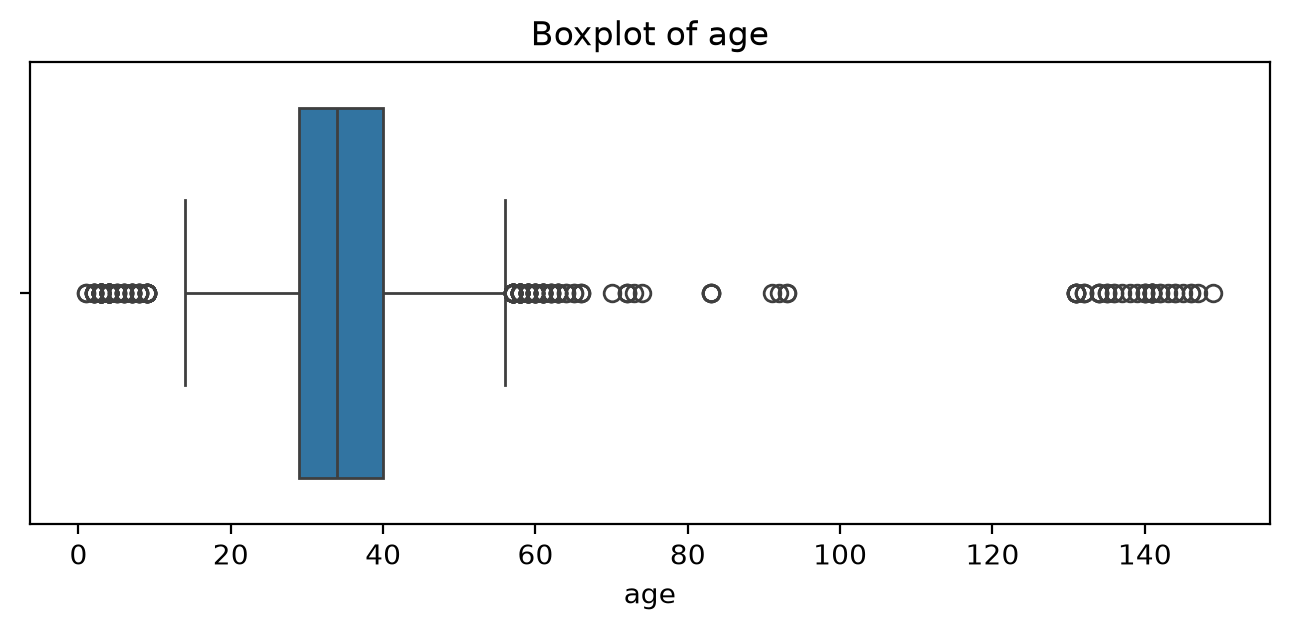

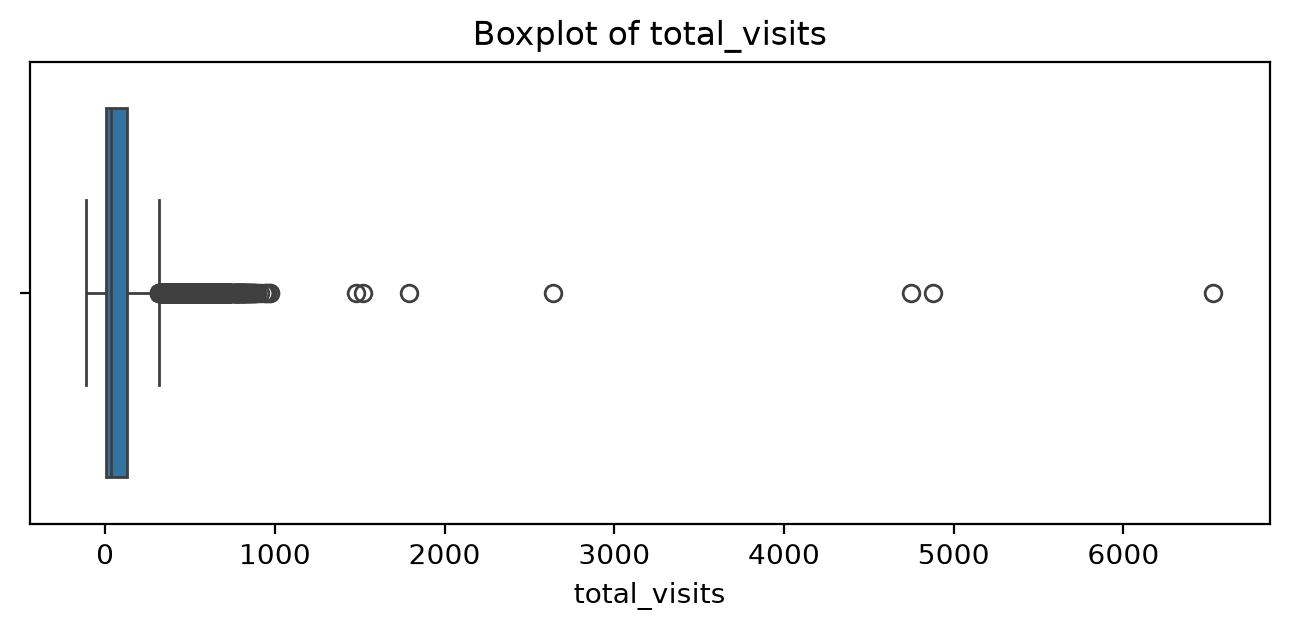

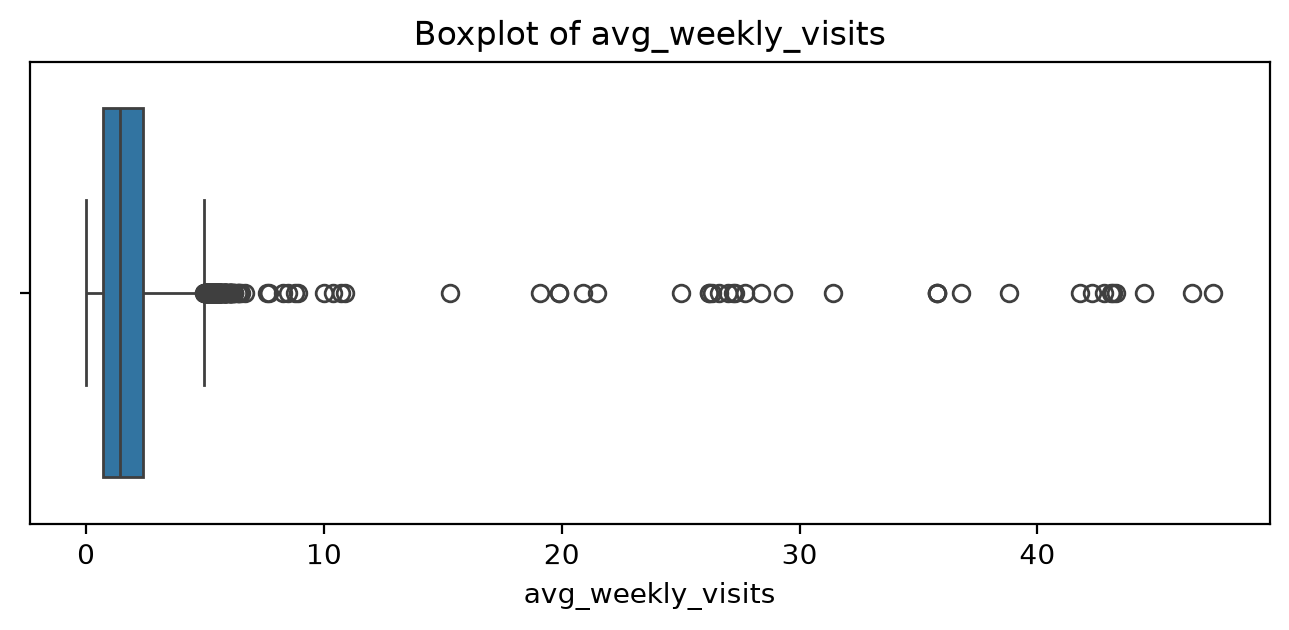

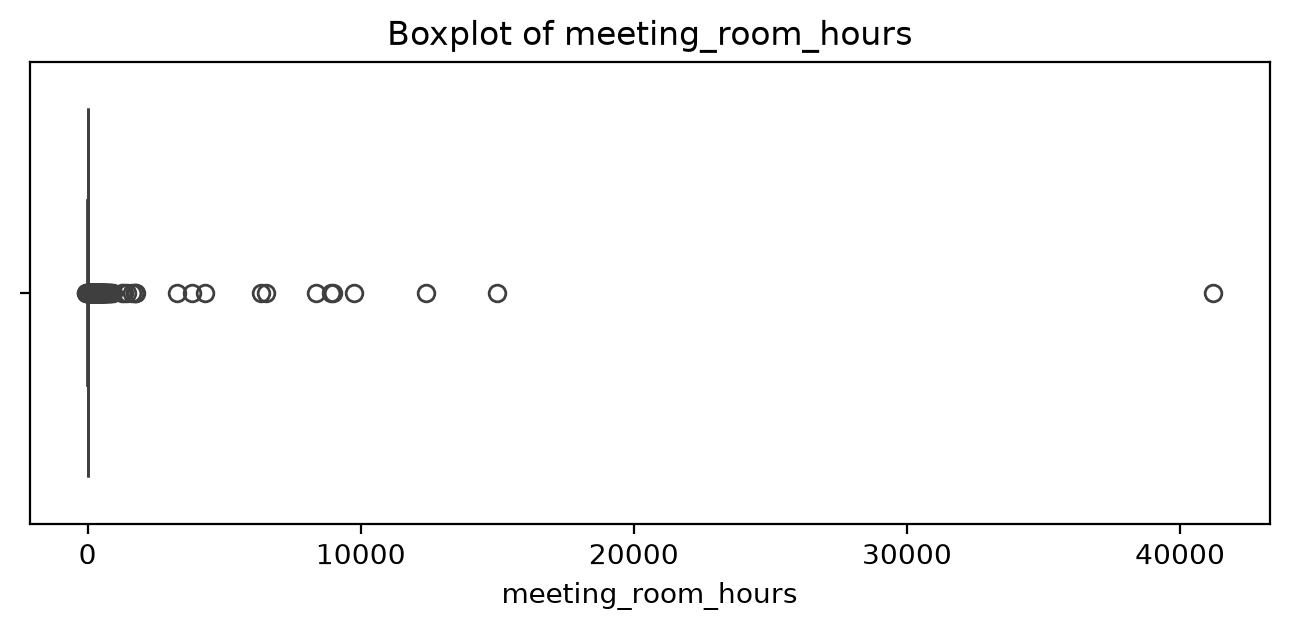

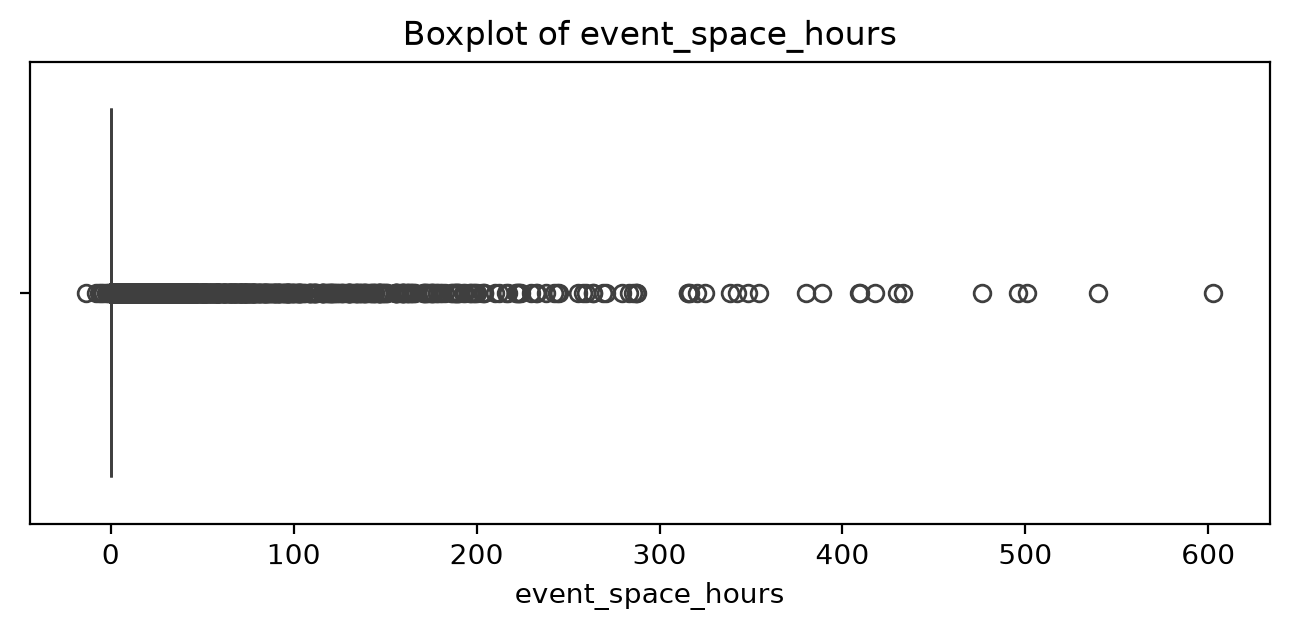

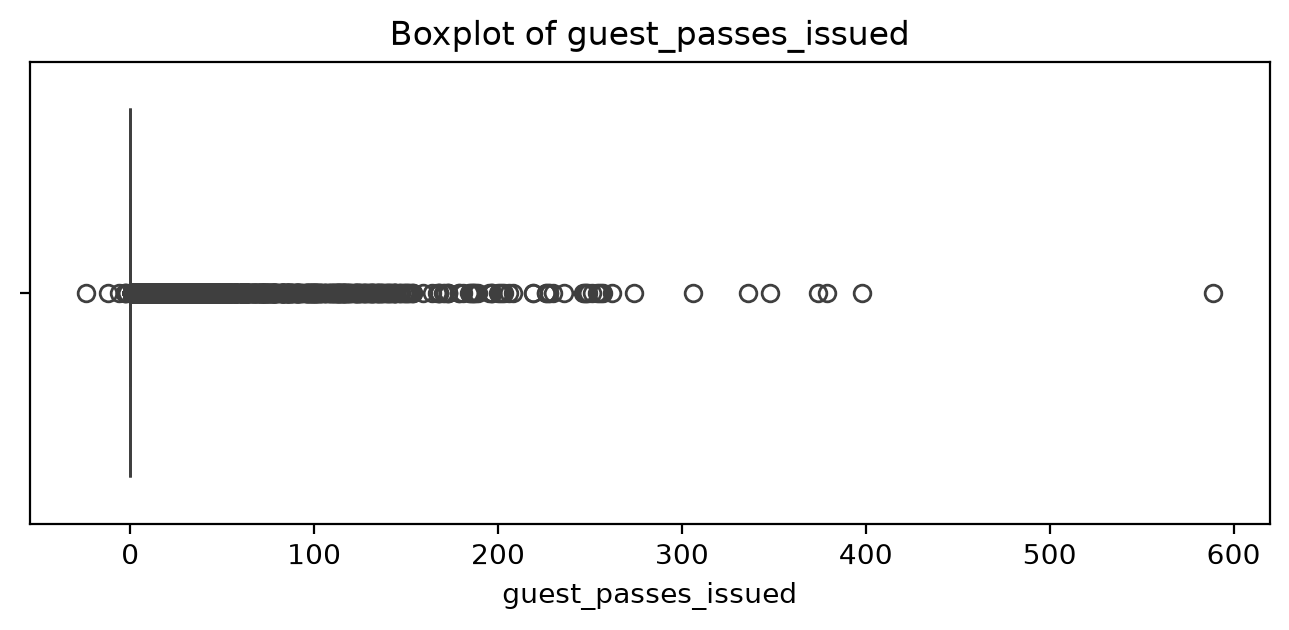

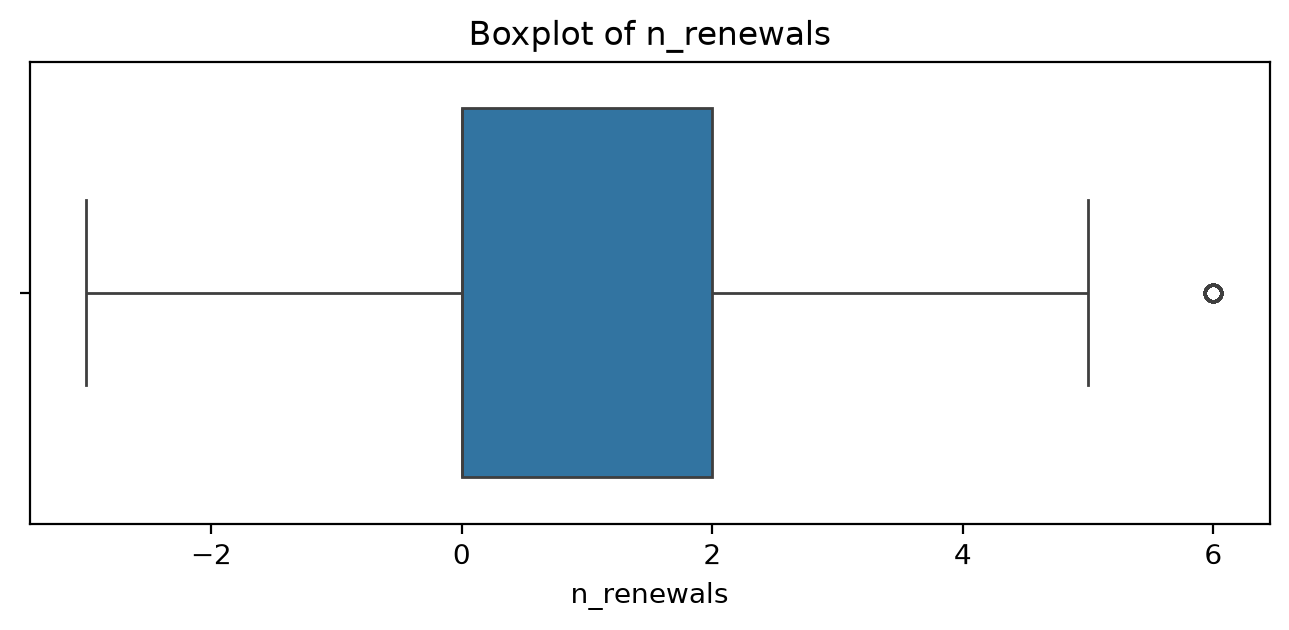

In [13]:
outlier_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals"
]

for col in outlier_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

For our variables:
- Age: outliers at very low or very high ages may be data-quality problems if they are unrealistic.
- Total visits: high outliers may be genuinely very active or long-term members.
- Average weekly visits: very high outliers may indicate unusually active members, but they should be checked for plausibility.
- Meeting room hours: high outliers may indicate members who use meeting rooms much more than others, which could be a meaningful customer profile.
- Event space hours: same idea; extreme users may represent a distinct behavioral group.
- Guest passes issued: high values may indicate members who frequently bring clients or guests.
- Number of renewals: high positive values may indicate loyal long-term members, while negative values would be a data-quality problem.
  

## 6. Correlation and redundancy

Lets try to apply a Spearman correlation to our data to see which behaviors move together and which variables might be redundant when we later build the clustering model.
Spearman correlation was used because several numerical variables contain extreme values. As a rank-based measure, Spearman is less sensitive to outliers and can identify monotonic relationships that are not necessarily linear.

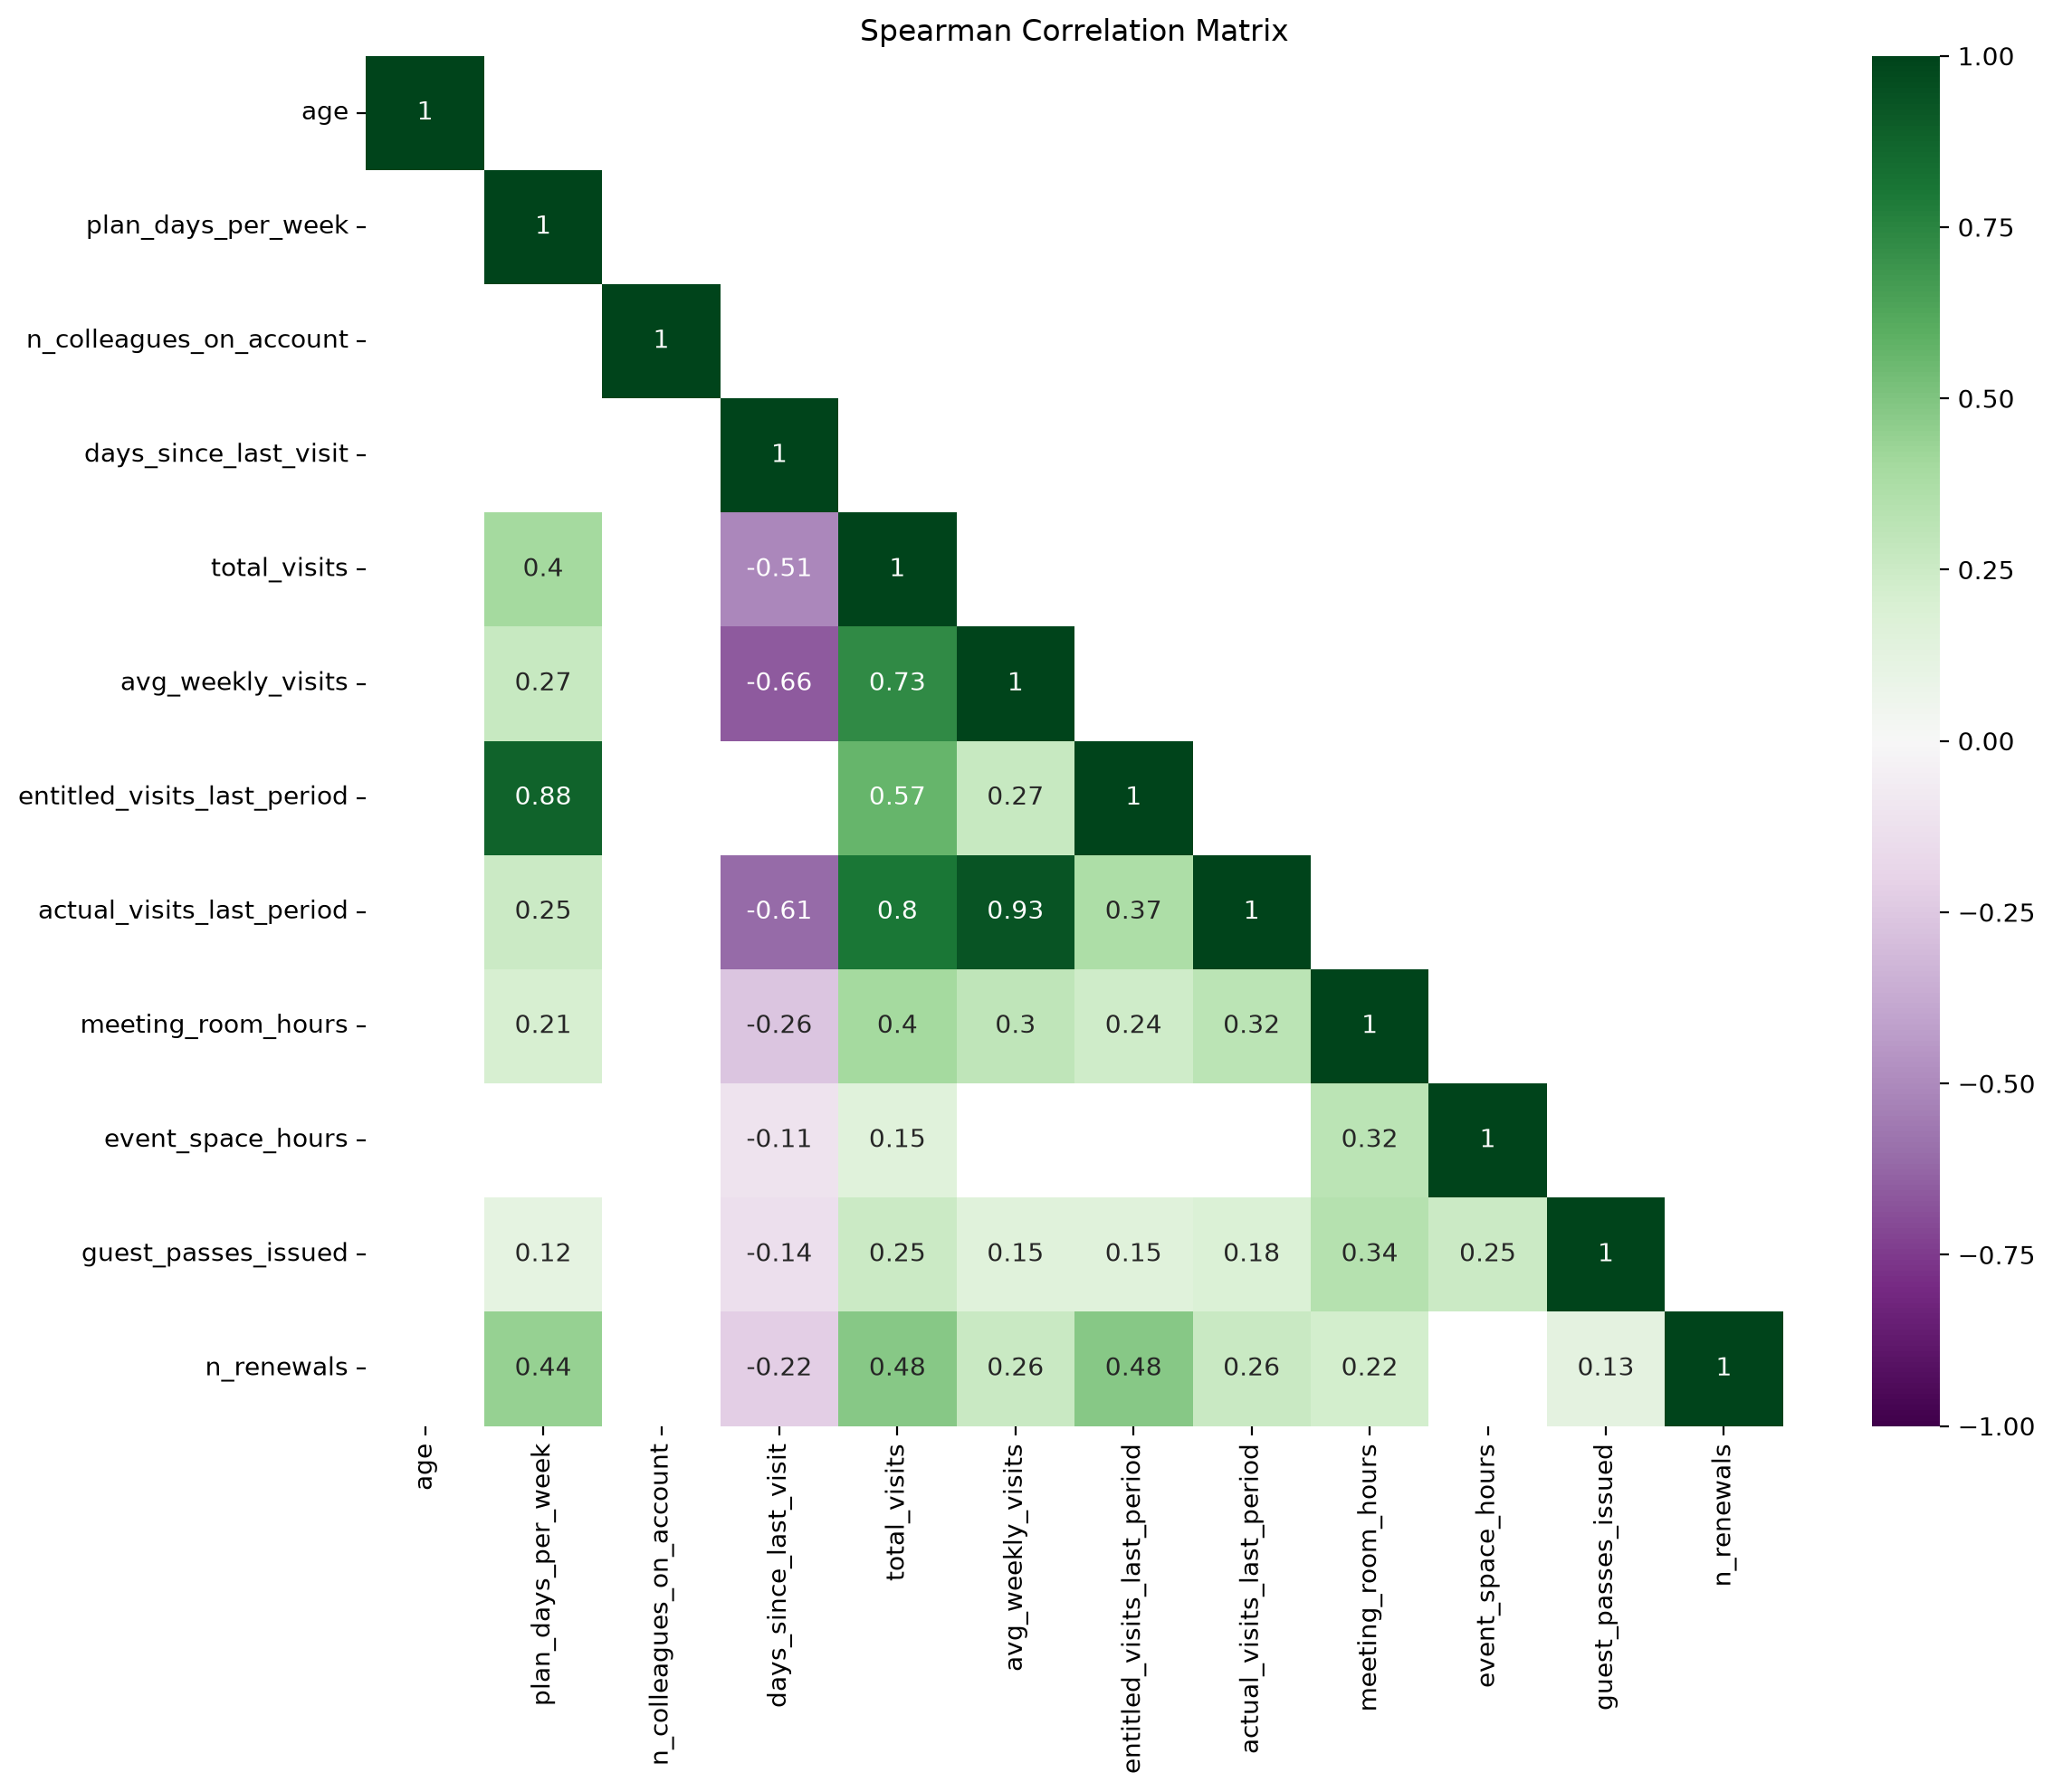

In [14]:
#Variables i want to include in the correlation analysis, aka numeric variables
corr_cols = [
    "age", "plan_days_per_week", "n_colleagues_on_account",
    "days_since_last_visit", "total_visits", "avg_weekly_visits",
    "entitled_visits_last_period", "actual_visits_last_period",
    "meeting_room_hours", "event_space_hours", "guest_passes_issued",
    "n_renewals"
]
corr = df[corr_cols].corr(method="spearman").round(2)
plt.figure(figsize=(12, 10)) #size of the graph
sns.heatmap(
    corr,
    mask=(~np.tril(np.ones_like(corr, dtype=bool))) | (corr.abs() < 0.10),
    #tril hides the upper traingle, upper triangle is True but Seaborn hides True cells, so we add the "~"
    annot=True,#write the correlation value inside each square 
    cmap='PRGn', #colour palette
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout() #helps prevent labels from overlapping or being cut off
plt.show()
# also the values close to zero(check distributions because they could still relate to eachother



#avg_weekly_visits ↔ actual_visits_last_period = 0.93
#Members with higher weekly visit frequency generally also have more actual visits in the recent period.
#people who rank high in average weekly visits also rank high on actual visits last period

#days_since_last_visit ↔ avg_weekly_visits = -0.66
#As the number of days since the last visit increases, weekly visit frequency generally decreases.

#Age shows little monotonic(means if one grows the other typically grows or decreases too)
#relationship with all variables according to Spearman correlation but it doesnt mean it has no relationship at all


Spearman correlation was used to examine monotonic relationships between numerical variables. The upper triangle was removed because the correlation matrix is symmetrical, and very weak correlations were hidden to improve readability. Strong correlations may indicate related or potentially redundant variables. However, correlations close to zero do not necessarily indicate the absence of a relationship, as non-linear patterns may still be present and should be investigated through distributions and other visualizations.

### 6.1 Age vs Average weekly visits 

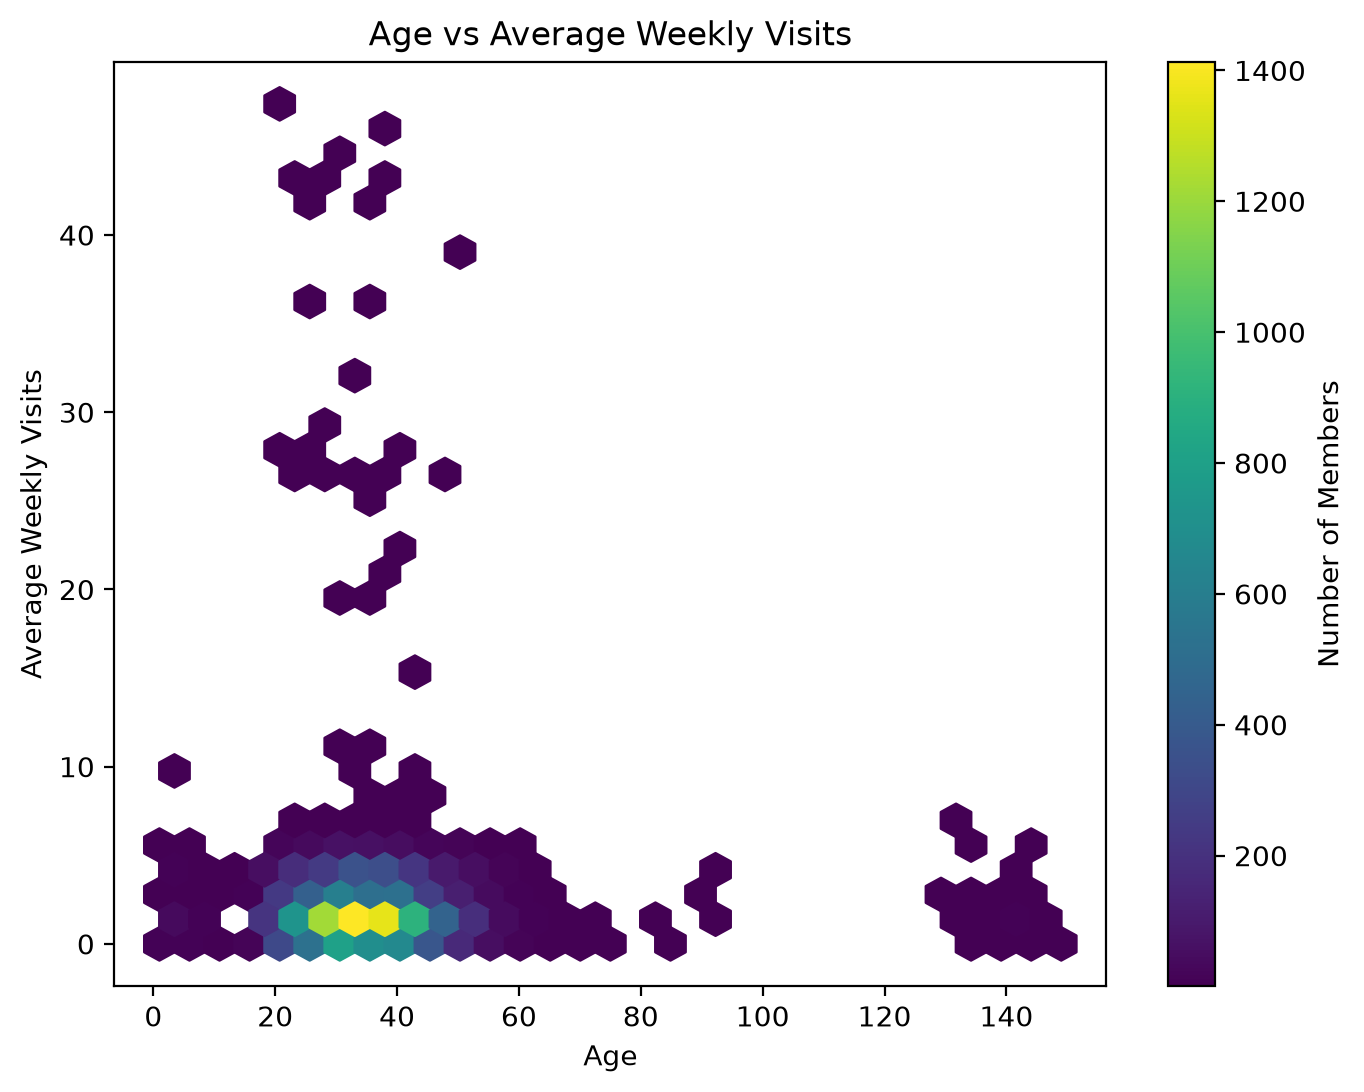

Spearman correlation: 0.01


In [15]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    df["age"],
    df["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Age")
plt.ylabel("Average Weekly Visits")
plt.title("Age vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = df["age"].corr(df["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

The hexbin plot does not suggest a clear increasing or decreasing relationship between age and average weekly visits. Instead, the observations are concentrated in particular areas of the distribution, showing that members with similar ages can have quite different levels of weekly activity.

### Number of colleagues on account vs meeting rooms hours

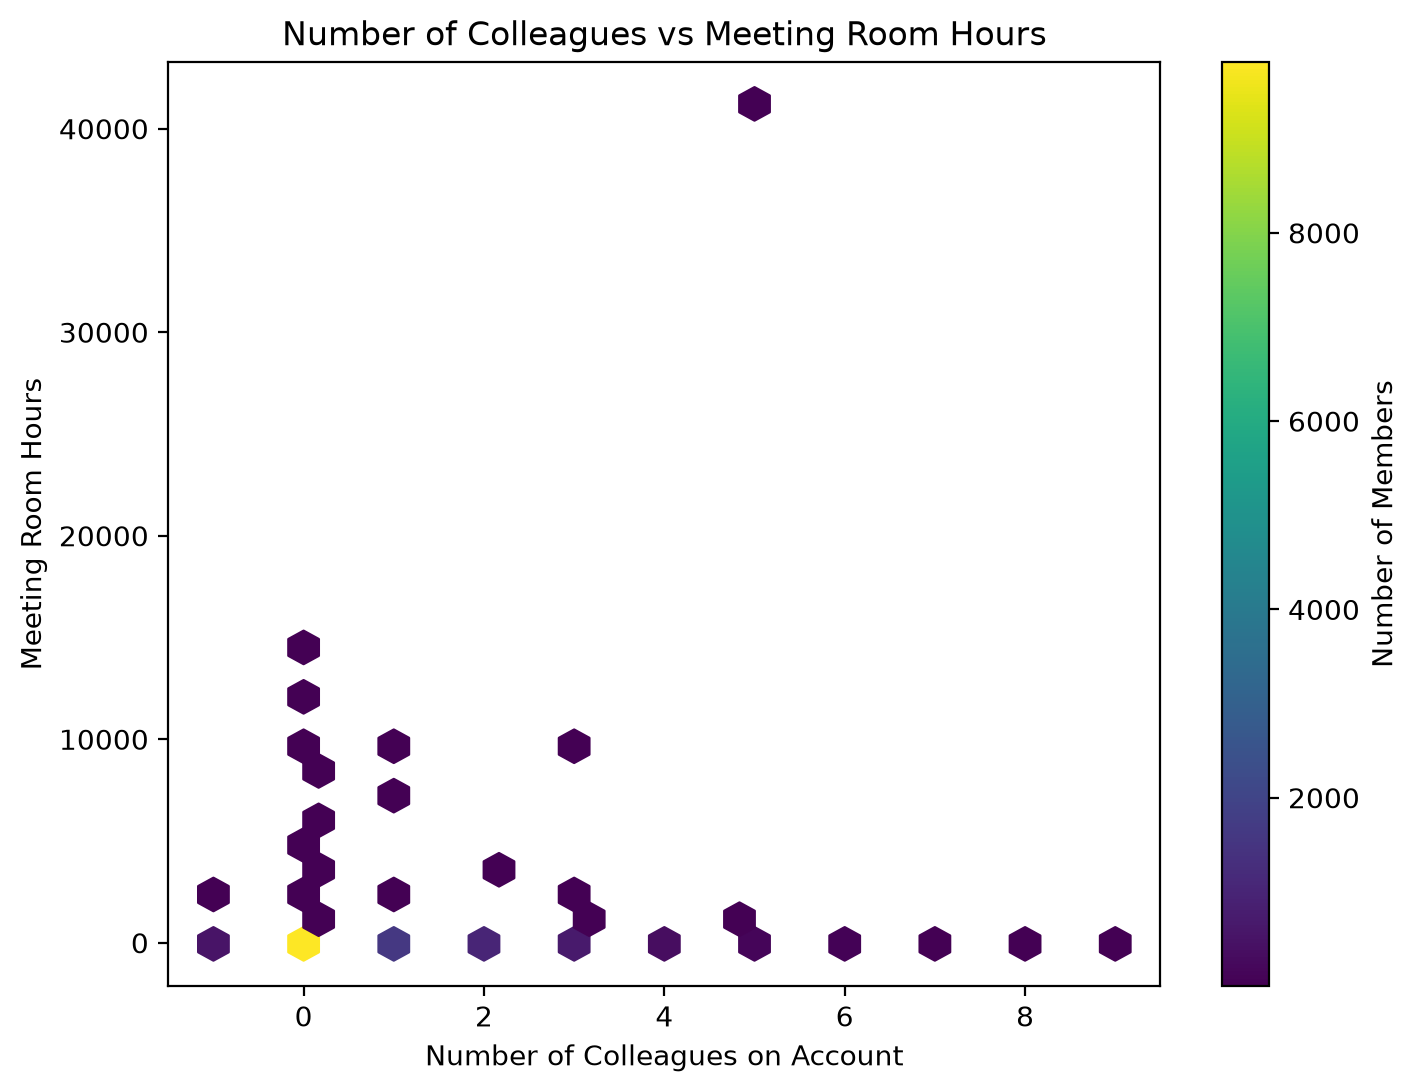

Spearman correlation: 0.01


In [16]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    df["n_colleagues_on_account"],
    df["meeting_room_hours"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Number of Colleagues on Account")
plt.ylabel("Meeting Room Hours")
plt.title("Number of Colleagues vs Meeting Room Hours")

plt.colorbar(label="Number of Members")
plt.show()
rho = df["n_colleagues_on_account"].corr(df["meeting_room_hours"], method="spearman")
print("Spearman correlation:", round(rho, 2))

No clear monotonic relationship is visible between the number of colleagues on an account and meeting-room usage. Most members are concentrated around low values for both variables. However, the graph reveals that there is extremely large meeting-room-hour values, plus a negative value for number of colleagues. Those are strong anomalies.

### Event space hours vs Average weekly visits

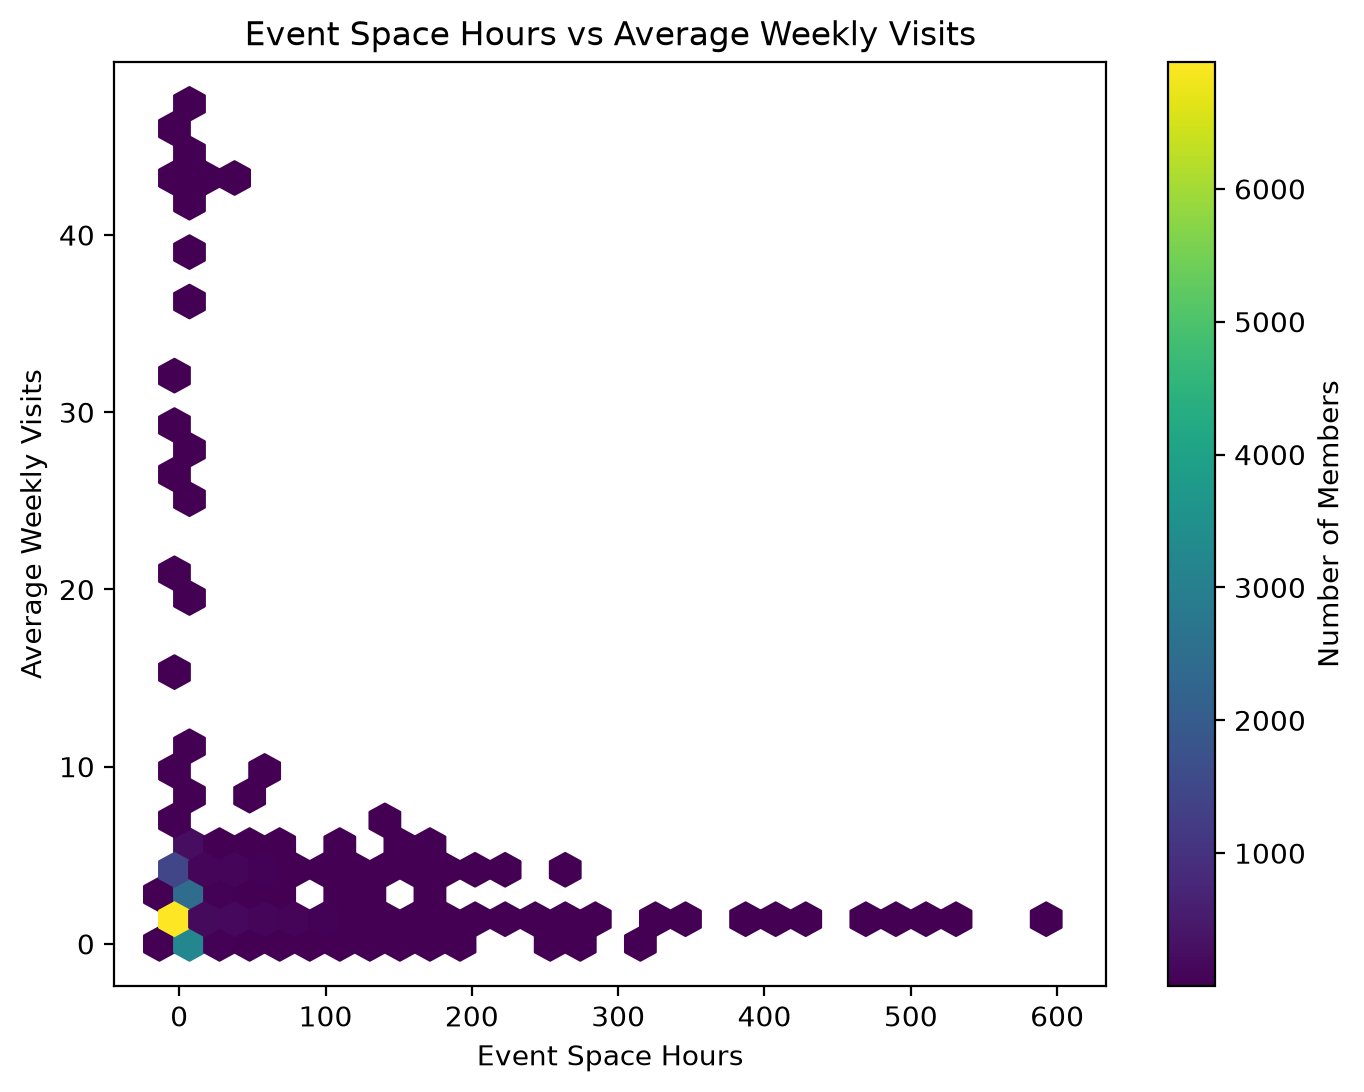

Spearman correlation: 0.07


In [17]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    df["event_space_hours"],
    df["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Event Space Hours")
plt.ylabel("Average Weekly Visits")
plt.title("Event Space Hours vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = df["event_space_hours"].corr(df["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

Event-space usage shows little evidence of a strong monotonic relationship with average weekly visits. Most members have low values for both variables, while high event-space usage is mainly associated with low weekly visits. This suggests that event-space hours may capture a different behavioral dimension from regular workspace attendance.

### Current interpretation

Based on the EDA so far, some variables seem more useful than others for distinguishing different types of members. We are not removing any variables yet. The goal is to identify which features look useful, which ones may contain similar information, and which ones have data-quality issues that should be considered before clustering.

In [18]:
feature_selection = pd.DataFrame({
    "Feature": [
        "member_id",
        "age",
        "gender",
        "industry",
        "country",
        "is_team_account",
        "n_colleagues_on_account",
        "plan_tier",
        "plan_days_per_week",
        "membership_start",
        "membership_end",
        "last_badge_swipe",
        "days_since_last_visit",
        "total_visits",
        "avg_weekly_visits",
        "entitled_visits_last_period",
        "actual_visits_last_period",
        "meeting_room_hours",
        "event_space_hours",
        "guest_passes_issued",
        "uses_meeting_rooms",
        "uses_event_space",
        "uses_guest_passes",
        "uses_print",
        "uses_mail_handling",
        "uses_phone_booths",
        "uses_day_passes",
        "uses_storage",
        "uses_bike_locker",
        "n_renewals",
        "lifetime_value"
    ],

    "Current view": [
        "Do not use directly",
        "Investigate",
        "Possible profiling feature",
        "Possible profiling feature",
        "Possible profiling feature",
        "Possible useful feature",
        "Useful with caution",
        "Useful after cleaning",
        "Useful with caution",
        "Use after transformation",
        "Use after transformation",
        "Use after transformation",
        "Useful with caution",
        "Useful with caution",
        "Useful",
        "Possible redundancy",
        "Possible redundancy",
        "Useful with caution",
        "Useful",
        "Useful with caution",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Possible useful feature",
        "Probably low usefulness",
        "Useful with caution",
        "Important with caution"
    ],

    "Reason": [
        "Identifier only",
        "Outliers + weak correlation",
        "Missing values + categories",
        "Category counts",
        "Missing values + categories",
        "Boolean summary",
        "Outliers + hexbin",
        "Category counts",
        "Outliers + correlation",
        "Variable meaning",
        "Suspicious dates",
        "Variable meaning",
        "Outliers + correlation",
        "Outliers + correlation",
        "Correlation",
        "Strong correlation",
        "Strong correlation",
        "Missing values + outliers",
        "Hexbin + outliers",
        "Missing values + outliers",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Boolean summary",
        "Almost all False",
        "Outliers + correlation",
        "Missing values + outliers + project goal"
    ]
})

feature_selection

,Feature,Current view,Reason
0,member_id,Do not use directly,Identifier only
1,age,Investigate,Outliers + weak correlation
2,gender,Possible profiling feature,Missing values + categories
3,industry,Possible profiling feature,Category counts
4,country,Possible profiling feature,Missing values + categories
5,is_team_account,Possible useful feature,Boolean summary
6,n_colleagues_on_account,Useful with caution,Outliers + hexbin
7,plan_tier,Useful after cleaning,Category counts
8,plan_days_per_week,Useful with caution,Outliers + correlation
9,membership_start,Use after transformation,Variable meaning


## Feature Engineering

New features are created from existing variables to capture member behaviour in a simpler and potentially more useful way for segmentation.

Two features are explored:
- **Visit utilization:** how much of the member's allowed visits were actually used.
- **Number of services used:** how many different additional services each member uses.

#### Visit utilization

In [19]:
df["visit_utilization"] = (
    df["actual_visits_last_period"] /
    df["entitled_visits_last_period"].replace(0, np.nan)
)

df["visit_utilization"].describe()

count    15455.000000
mean         0.517490
std          0.312224
min          0.000000
25%          0.238445
50%          0.517539
75%          0.804906
max          1.000000
Name: visit_utilization, dtype: float64

Member was allowed 20 visits, member actually used 10
- 10 / 20 = 0.5, they used 50% of their allowed visits 

Visit utilization measures the proportion of entitled visits that each member actually used. The average visit utilization is approximately 52%, meaning that members used, on average, about half of the visits available in their plan. There are members with very low and very high utilization, suggesting different levels of engagement with their membership plans.

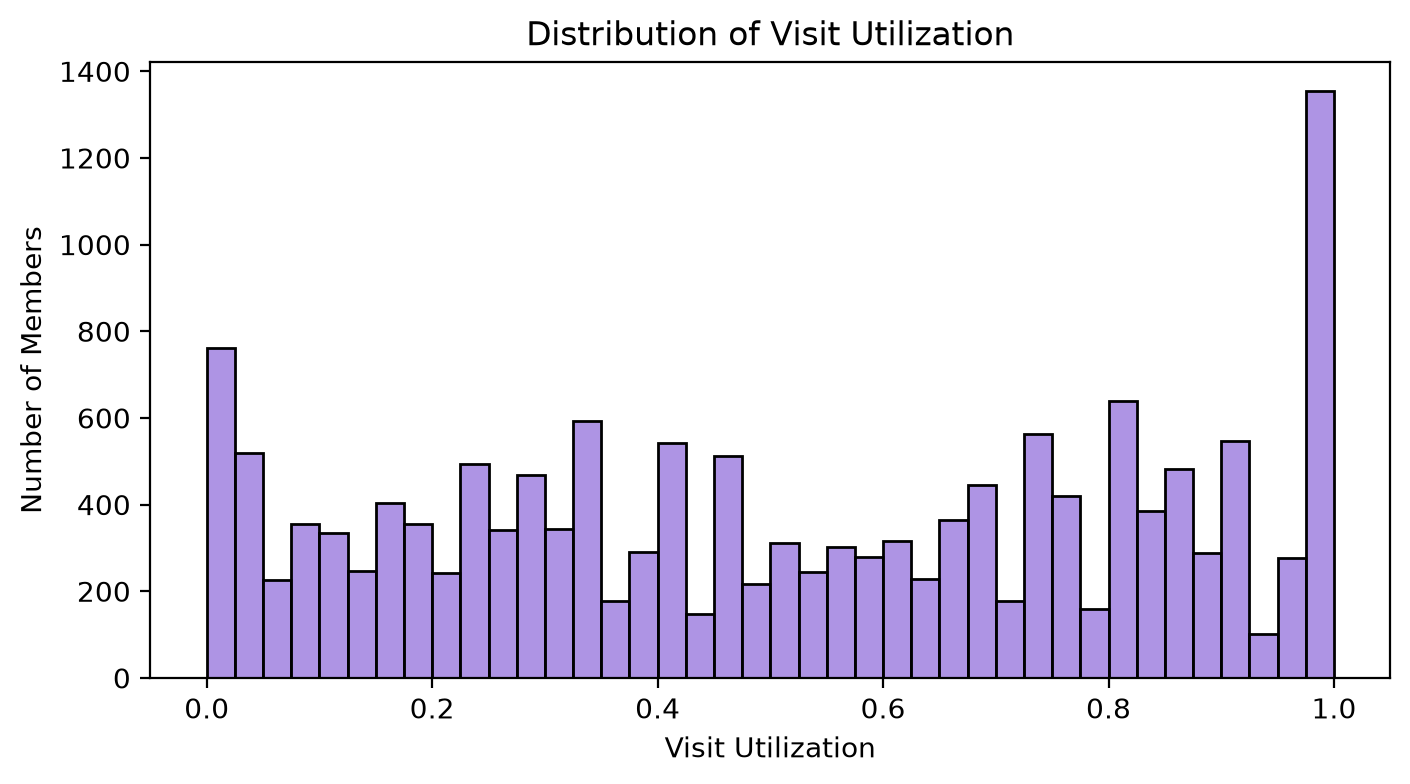

In [20]:
plt.figure(figsize=(8, 4))

sns.histplot(
    df["visit_utilization"].dropna(),
    bins=40,
    color="mediumpurple"
)

plt.title("Distribution of Visit Utilization")
plt.xlabel("Visit Utilization")
plt.ylabel("Number of Members")

plt.show()

#### Number of Services Used

This feature counts how many different additional services each member uses.
It may help distinguish members who mainly use the basic workspace from members
who make broader use of ACDC's services.

In [21]:
service_cols = [
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker"
]

df["n_services_used"] = df[service_cols].sum(axis=1)

df["n_services_used"].value_counts().sort_index()

n_services_used
0    3091
1    4645
2    3240
3    2141
4    1397
5     690
6     224
7      34
8       3
Name: count, dtype: int64

The most common number of services used is 1, with 4,645 members.
Most members use only a small number of additional services, while members
using many different services are much less common. This may help distinguish
between members with basic service usage and members with more engagement
with ACDC's services.

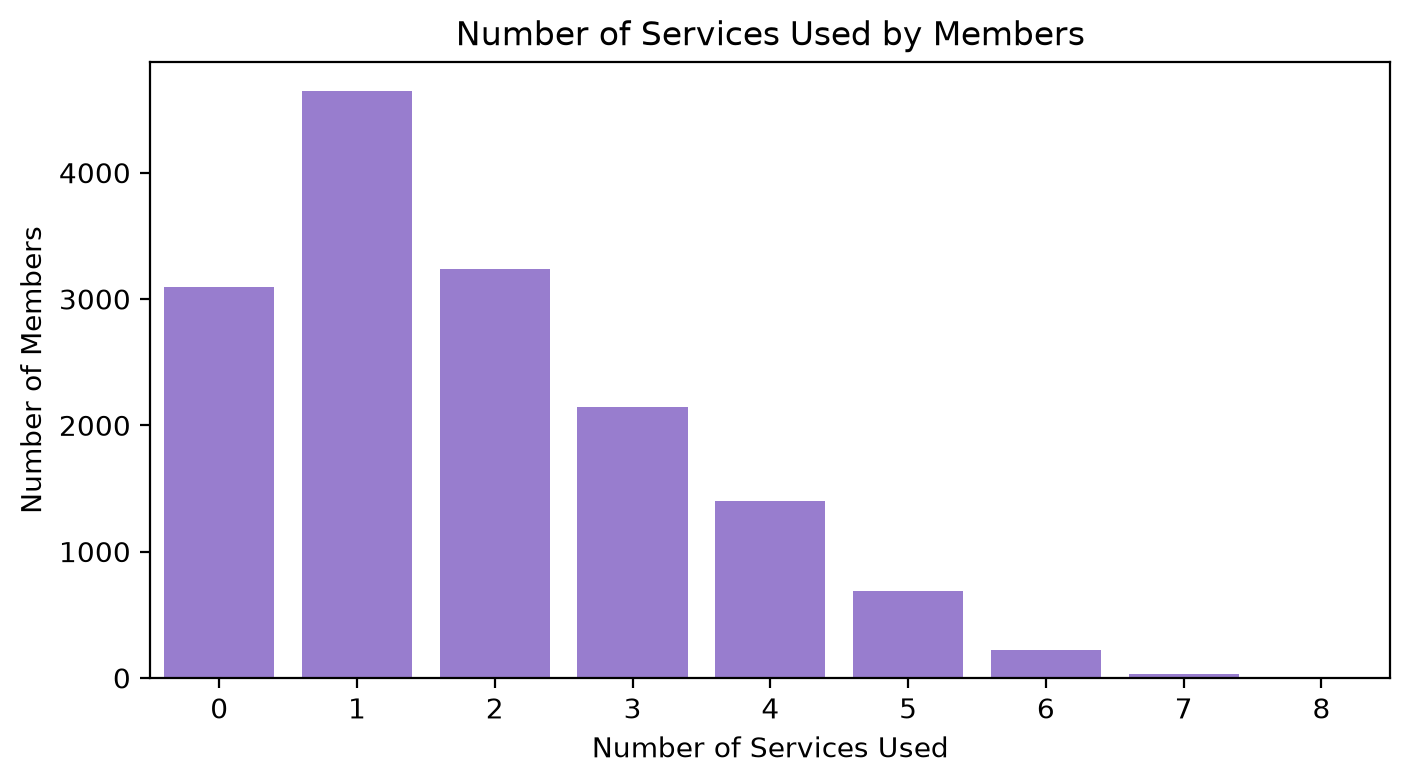

In [22]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=df,
    x="n_services_used",
    color="mediumpurple"
)

plt.title("Number of Services Used by Members")
plt.xlabel("Number of Services Used")
plt.ylabel("Number of Members")

plt.show()

# Behavioral Analysis

### Team vs Individual Accounts

We compare team and individual accounts to investigate whether they show different patterns of workspace activity, service usage and engagement. These differences may help identify meaningful customer profiles for segmentation and may provide useful information for ACDC when designing services or membership offers.

#### Number of Team and Individual Accounts

In [24]:
df["is_team_account"].value_counts()

is_team_account
False    11112
True      4353
Name: count, dtype: int64

#### Percentage of Team and Individual Accounts

In [25]:
df["is_team_account"].value_counts(normalize=True) * 100

is_team_account
False    71.85257
True     28.14743
Name: proportion, dtype: float64

Most ACDC members have individual accounts, representing approximately 72% of the dataset, while team accounts represent around 28%. Although team accounts are a smaller group, they still represent a substantial proportion of customers and may show different usage patterns and business needs.

#### Behaviour Comparison Between Team and Individual Accounts

In [26]:
team_metrics = [
    "total_visits",
    "avg_weekly_visits",
    "visit_utilization",
    "meeting_room_hours",
    "guest_passes_issued",
    "n_services_used",
    "n_renewals"
]

df.groupby("is_team_account")[team_metrics].median().T

is_team_account,False,True
total_visits,33.0,37.0
avg_weekly_visits,1.42,1.45
visit_utilization,0.517539,0.517539
meeting_room_hours,0.0,0.0
guest_passes_issued,0.0,0.0
n_services_used,1.0,2.0
n_renewals,0.0,0.0


Team accounts use more services overall, with a median of 2 services compared with 1 for individual accounts.

For the other variables, the differences are small. Team accounts have slightly more total visits, but weekly visits and visit utilization are very similar between the two groups.

Meeting room hours, guest passes and renewals have a median of 0 for both groups, so we may need to look at these variables in a different way.

#### Service Usage by Account Type

In [27]:
service_usage = (
    df.groupby("is_team_account")[service_cols]
      .mean()
      .T * 100
)

service_usage

is_team_account,False,True
uses_meeting_rooms,33.828294,34.550884
uses_event_space,11.834053,12.083620
uses_guest_passes,18.214543,18.148403
uses_print,32.559395,31.656329
uses_mail_handling,22.714183,23.891569
uses_phone_booths,25.845932,25.821273
uses_day_passes,21.643269,22.765909
uses_storage,14.947804,14.587641
uses_bike_locker,0.170986,0.160809


Team and individual accounts use ACDC services in very similar ways. The percentage using each service is almost the same for both groups.

The median number of services used is slightly different, but the overall distribution is very similar. This suggests that being a team or individual account may not strongly affect service usage.

#### Distribution of Number of Services Used by Account Type

In [28]:
service_count_distribution = pd.crosstab(
    df["n_services_used"],
    df["is_team_account"],
    normalize="columns"
) * 100

service_count_distribution

is_team_account,False,True
n_services_used,,
0,20.104392,19.687572
1,30.381569,29.152309
2,20.644348,21.732139
3,13.561915,14.564668
4,9.107271,8.844475
5,4.499640,4.364806
6,1.448884,1.447278
7,0.233981,0.183781
8,0.017999,0.022973


The distribution of the number of services used is very similar for team and individual accounts. In both groups, most members use between 0 and 3 services, while only a small percentage use many services.

This confirms that team status does not seem to strongly affect the overall number of services used.

## Plan Tier Analysis

We compare members across different plan tiers to understand whether membership type is associated with different levels of activity, utilization and service usage.

#### Original Plan Tier Categories

In [29]:
df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

The `plan_tier` variable contains different spellings and capitalizations for the same plans. These need to be standardized before comparing plan behaviour.

#### Standardizing Plan Tier Labels

In [30]:
df["plan_tier_clean"] = (
    df["plan_tier"]
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .replace({
        "hotdesk": "hot_desk",
        "fulltime": "full_time",
        "dedicateddesk": "dedicated_desk",
        "privateoffice": "private_office"
    })
)

#### Cleaned Plan Tier Categories

In [31]:
df["plan_tier_clean"].value_counts(dropna=False)

plan_tier_clean
flex              5453
hot_desk          5215
full_time         2475
dedicated_desk    1552
private_office     665
NaN                105
Name: count, dtype: int64

#### Behaviour Comparison Across Plan Tiers

In [32]:
plan_order = [
    "hot_desk",
    "flex",
    "dedicated_desk",
    "full_time",
    "private_office"
]

plan_metrics = [
    "total_visits",
    "avg_weekly_visits",
    "visit_utilization",
    "n_services_used",
    "n_renewals"
]

plan_comparison = (
    df.groupby("plan_tier_clean")[plan_metrics]
      .median()
      .reindex(plan_order)
)

plan_comparison

,total_visits,avg_weekly_visits,visit_utilization,n_services_used,n_renewals
plan_tier_clean,,,,,
hot_desk,10.0,0.96,0.464486,1.0,0.0
flex,44.0,1.89,0.574933,1.0,0.0
dedicated_desk,396.0,3.86,0.735971,3.0,2.0
full_time,38.0,1.61,0.333572,2.0,1.0
private_office,131.0,1.04,0.147856,3.0,2.0


There are clear differences in behaviour across plan tiers.

Dedicated desk members appear to be the most active, with the highest weekly visits and visit utilization. They also use more services and have more renewals.

Private office members also use several services and have more renewals, but their visit utilization is much lower. Flex members have relatively high utilization, while hot desk members show lower overall activity.

These differences suggest that plan tier may be relevant for understanding different types of ACDC customers.

#### Visit Utilization by Plan Tier

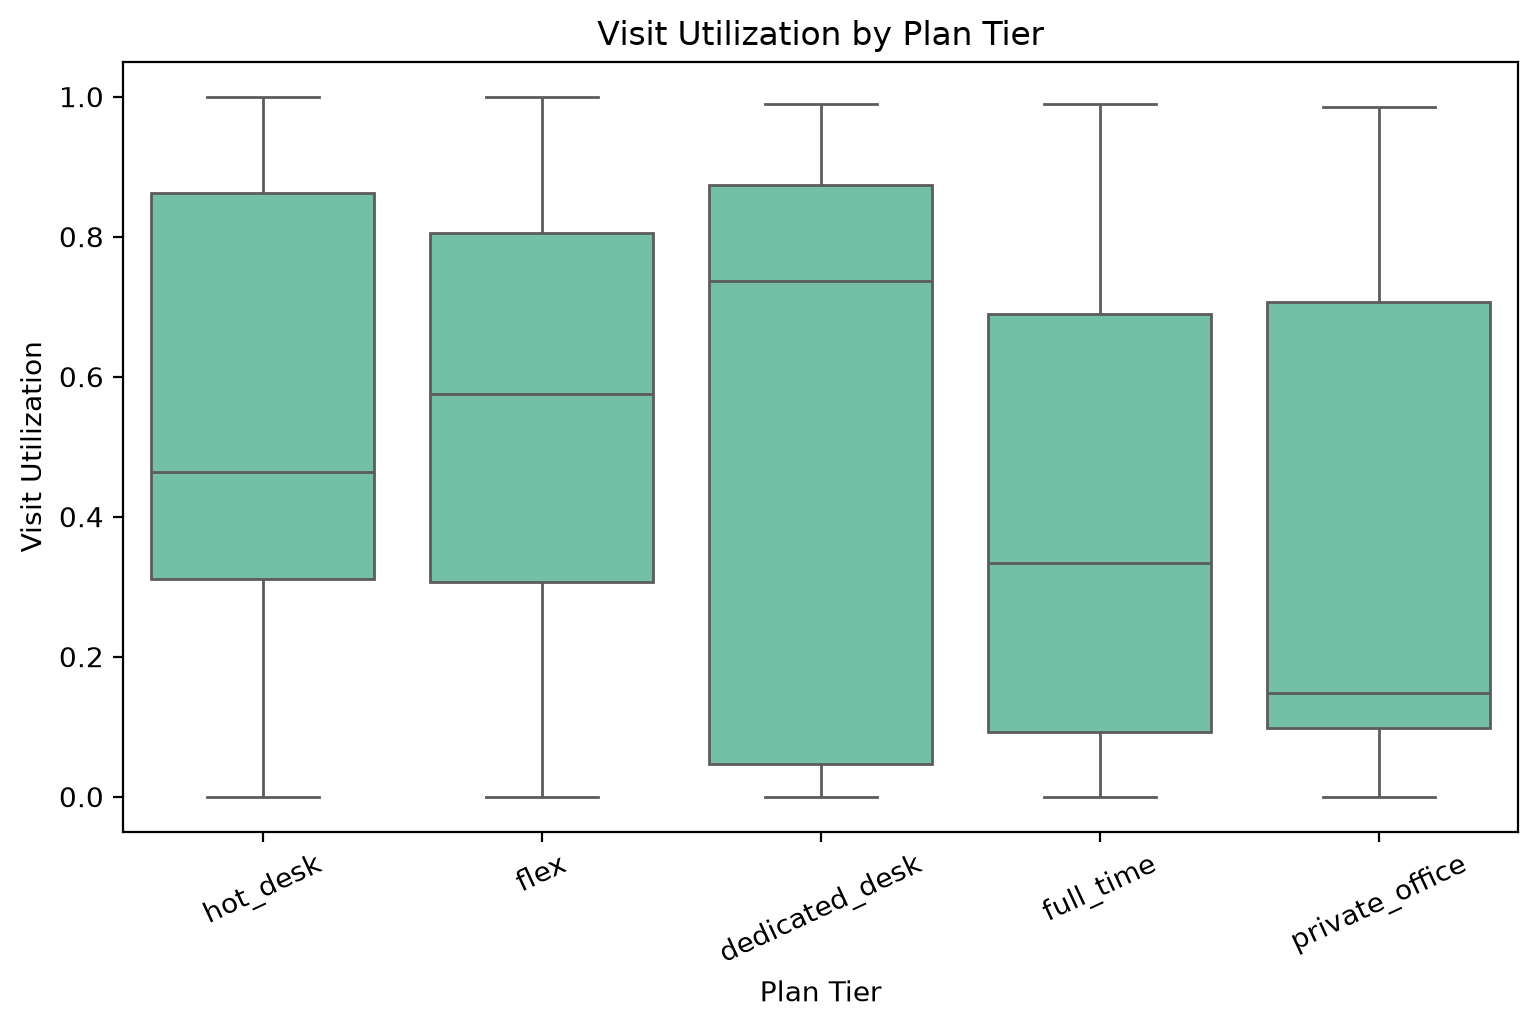

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="plan_tier_clean",
    y="visit_utilization",
    order=plan_order,
    color="mediumaquamarine"
)

plt.title("Visit Utilization by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Visit Utilization")
plt.xticks(rotation=25)

plt.show()

Visit utilization differs across plan tiers. Dedicated desk and flex members show higher median utilization, while full time and private office members have lower median utilization.

There is also a wide spread within some plans, meaning that members on the same plan can still have very different usage levels. This suggests that plan tier may help explain customer behaviour, but it does not fully determine how actively a member uses their plan.

#### Number of Services Used by Plan Tier

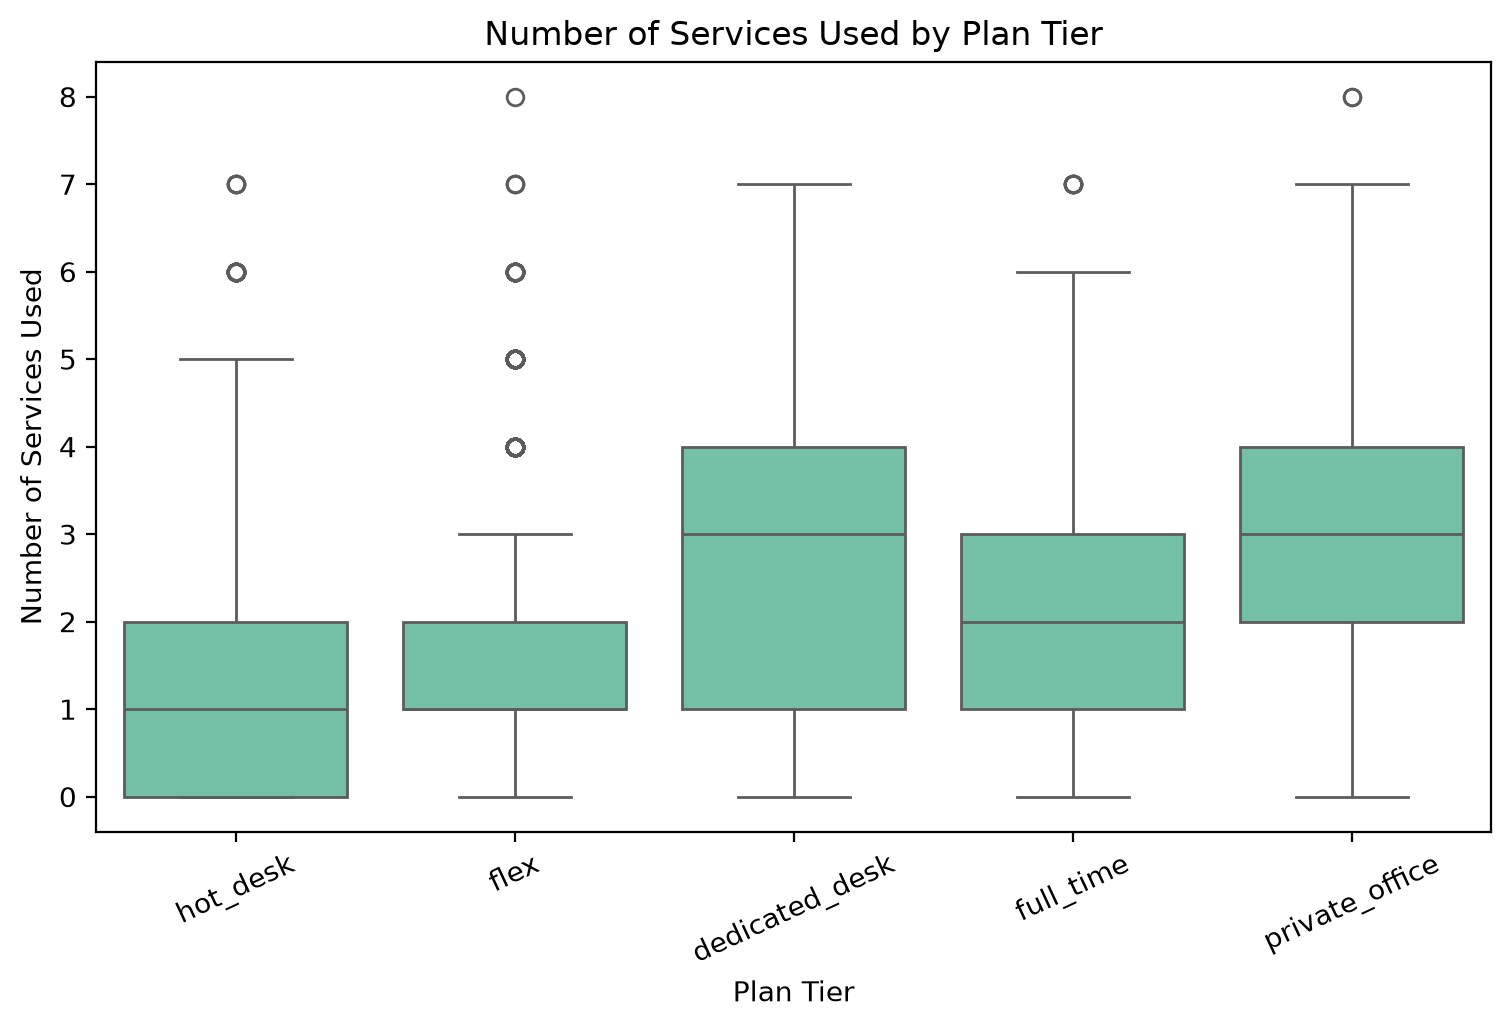

In [38]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="plan_tier_clean",
    y="n_services_used",
    order=plan_order,
    color="mediumaquamarine"
)

plt.title("Number of Services Used by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Number of Services Used")
plt.xticks(rotation=25)

plt.show()

Members on dedicated desk and private office plans tend to use a wider range of ACDC services, with a median of around 3 services. Hot desk and flex members generally use fewer services.

This suggests that members on higher plan tiers may be more broadly engaged with ACDC's services, while members on more basic plans tend to use a smaller range of additional services.

#### Average Weekly Visits by Plan Tier

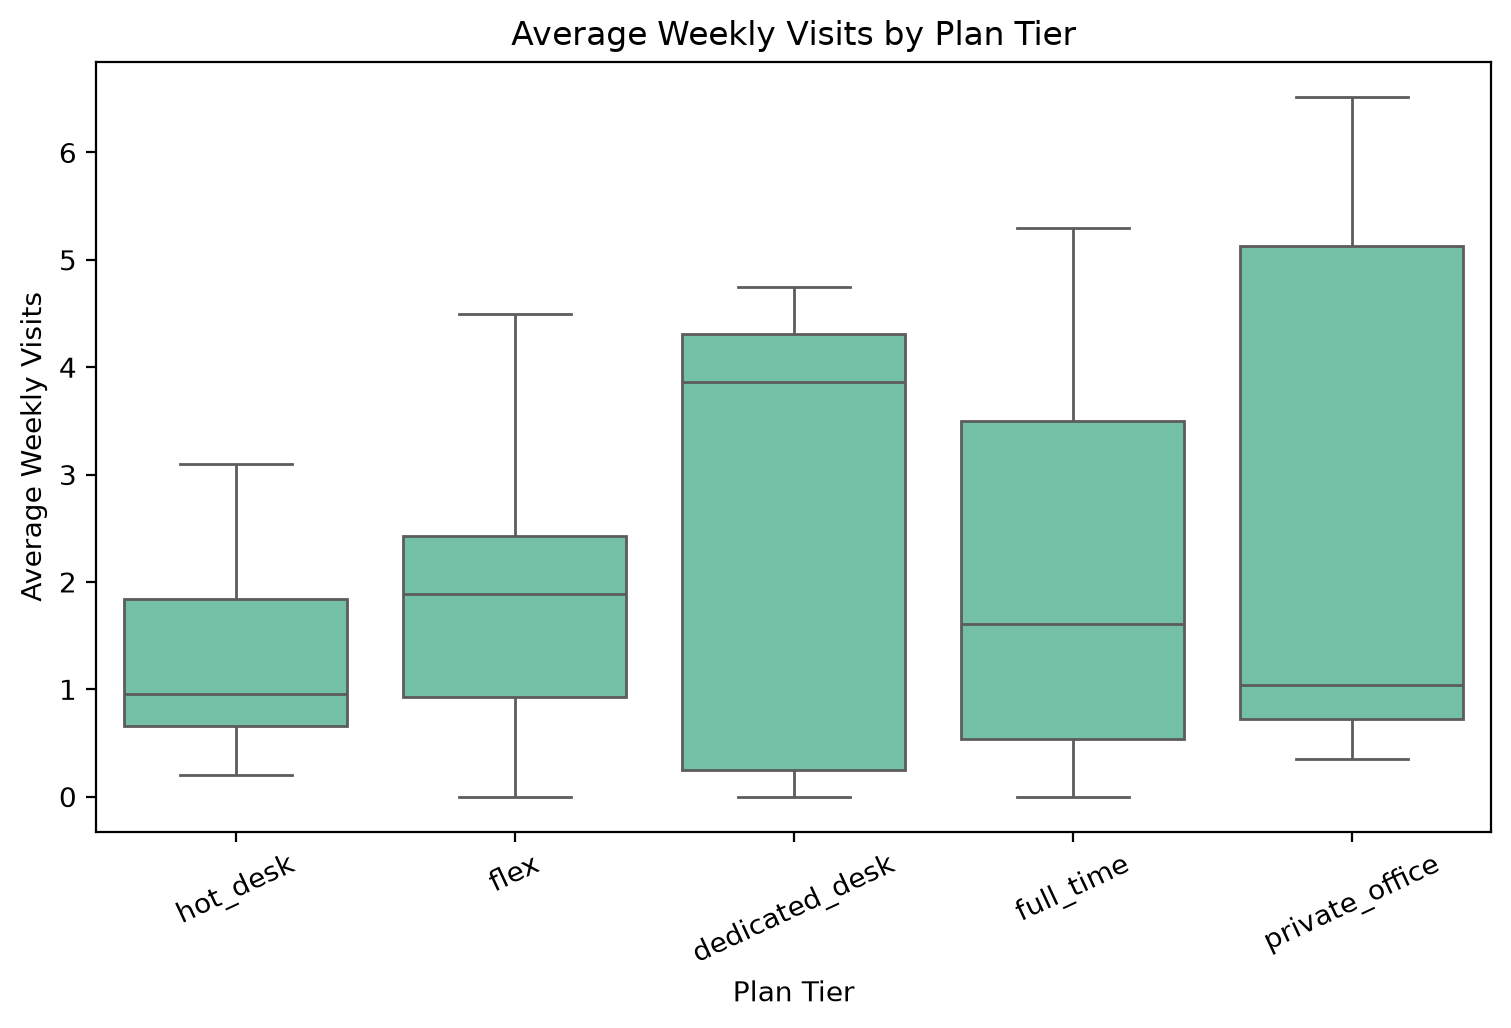

In [37]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="plan_tier_clean",
    y="avg_weekly_visits",
    order=plan_order,
    color="mediumaquamarine",
    showfliers=False
)

plt.title("Average Weekly Visits by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Average Weekly Visits")
plt.xticks(rotation=25)

plt.show()

Extreme values are not displayed in this plot to make the differences between the typical usage patterns of each plan easier to see. These values remain in the dataset and were identified during the previous outlier analysis.

## Main Findings from Behavioral Analysis

-Team and individual accounts behave quite similarly, so account type alone may not be very useful for distinguishing different types of ACDC customers.

-Plan tier shows clearer differences. Dedicated desk members tend to visit more often and use more of the visits included in their plan, while private office members visit less often but use a wider range of services.

-This suggests that different plans may reflect different customer needs. Some members seem to value frequent access to the workspace, while others may value the additional services and benefits that come with their membership. These differences could be useful for ACDC when understanding customer groups and adapting its services to them.